# Guía práctica 3

## Ejercicio 3

In [2]:
from matplotlib.pyplot import close, show, subplots
from numpy import abs, allclose, angle, arange, imag, pi, real
from numpy.fft import fft, ifft

In [3]:
def plot_dft(h, name):
    """Plot Re, Im, magnitude and phase of the DFT of h as a 2x2 stem grid."""
    H = fft(h)
    k = arange(H.size)

    phase = angle(H)
    phase[abs(H) < 1e-10] = 0.0  # Phase is undefined where the magnitude vanishes.

    panels = [
        ("Re{X[k]}", real(H)),
        ("Im{X[k]}", imag(H)),
        ("|X[k]|", abs(H)),
        ("arg{X[k]} / pi", phase / pi),
    ]

    fig, axes = subplots(2, 2, figsize=(10, 6), dpi=150)
    for ax, (label, values) in zip(axes.ravel(), panels):
        ax.stem(k, values, linefmt="C0-", markerfmt="C0o", basefmt="#999999")
        ax.set_title(label)
        ax.set_xlabel("k")
        ax.grid(True, alpha=0.3)

    fig.suptitle(name)
    fig.tight_layout()
    show()
    close(fig)
    return H

In [4]:
def check_symmetry(h, name):
    """Print the circular symmetry of h and the resulting symmetry of its DFT."""
    H = fft(h)
    k = arange(H.size)
    Hm = H[(-k) % H.size]  # X[-k], i.e. X[N-k].
    hm = h[(-k) % H.size]  # h[-n].

    print(name)
    print(f"  h circularmente par   : {allclose(h, hm)}")
    print(f"  h circularmente impar : {allclose(h, -hm)}")
    print(f"  X[-k] = conj(X[k])    : {allclose(Hm, H.conj())}")
    print(f"  Re par                : {allclose(real(H), real(Hm))}")
    print(f"  Im impar              : {allclose(imag(H), -imag(Hm))}")
    print(f"  |X| par               : {allclose(abs(H), abs(Hm))}")
    print(f"  X real (Im == 0)      : {allclose(imag(H), 0)}")
    print(f"  |X| constante         : {allclose(abs(H), abs(H)[0])}")

In [5]:
from numpy import array

h_a = array([1, 0, 0, 0, 0, 0, 0, 0])  # Impulso.
h_b = array([1, 1, 1, 1, 1, 1, 1, 1])  # Todos unos.
h_c = array([0, 0, 0, 1, 0, 0, 0, 0])  # Impulso corrido (n0 = 3).
h_d = array([1, 1, 1, 0, 0, 0, 0, 0])  # Rectangulo.
h_e = array([1, 1, 0, 0, 0, 0, 0, 1])  # Rectangulo simetrico (circular).

### (a) Impulso  $h[n] = [1\,0\,0\,0\,0\,0\,0\,0]$

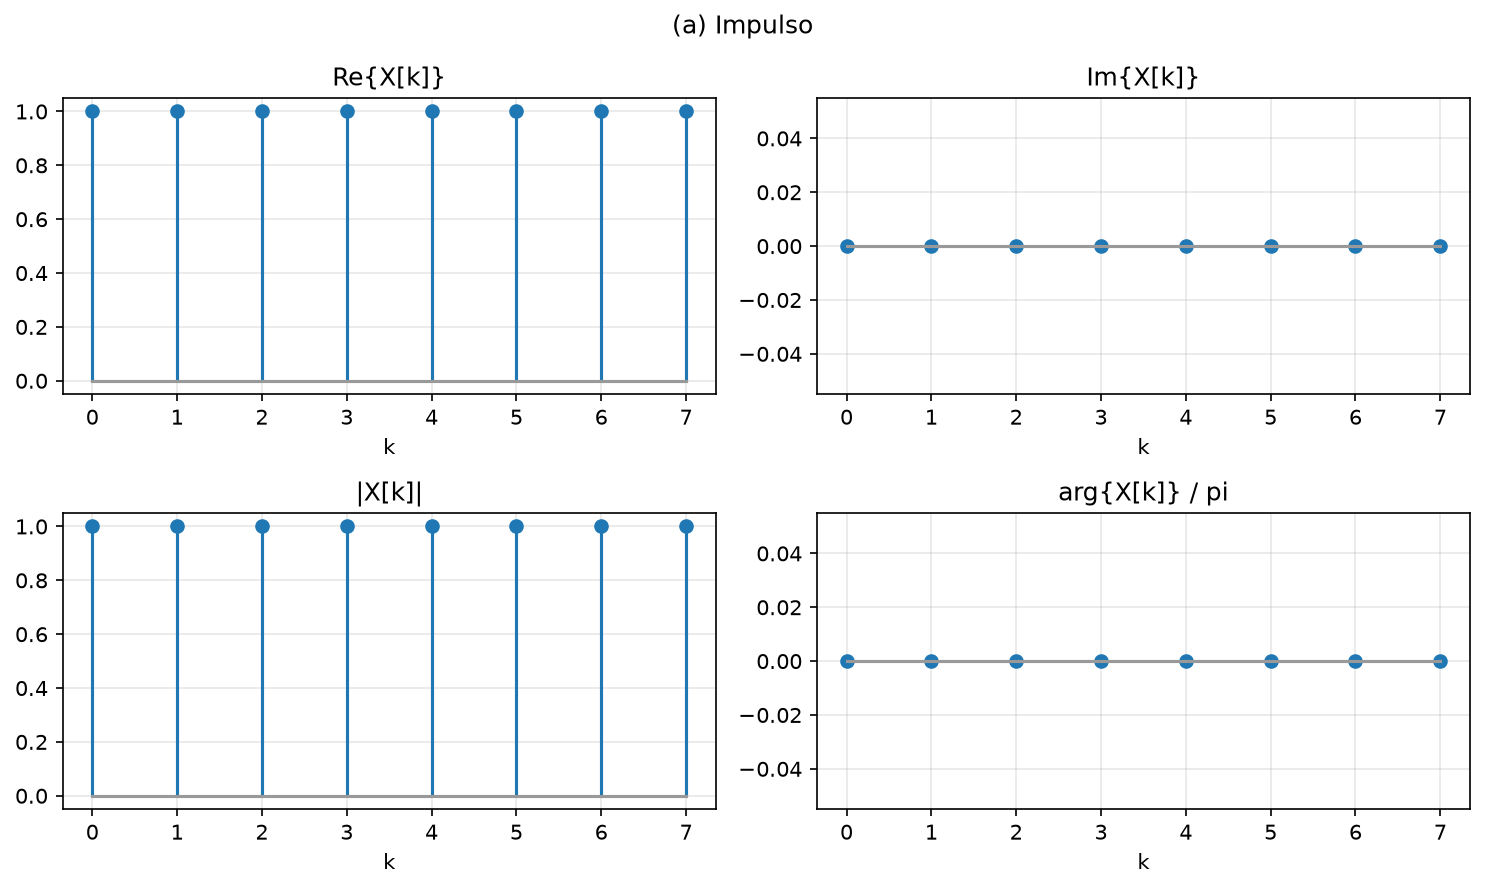

(a)
  h circularmente par   : True
  h circularmente impar : False
  X[-k] = conj(X[k])    : True
  Re par                : True
  Im impar              : True
  |X| par               : True
  X real (Im == 0)      : True
  |X| constante         : True


In [6]:
H_a = plot_dft(h_a, "(a) Impulso")
check_symmetry(h_a, "(a)")

La suma de la TDF tiene un solo término no nulo, el de $n = 0$, y ahí la exponencial vale
$e^{0} = 1$ para cualquier $k$. Entonces

$$X^d[k] = 1 \qquad \forall k$$

El impulso está concentrado en un único instante, por ende su espectro queda
repartido por igual en todas las frecuencias. $h[n]$ es circularmente par (su única muestra no nula está en $n=0$), por eso $X^d[k]$ es real y par.

### (b) Constante  $h[n] = [1\,1\,1\,1\,1\,1\,1\,1]$

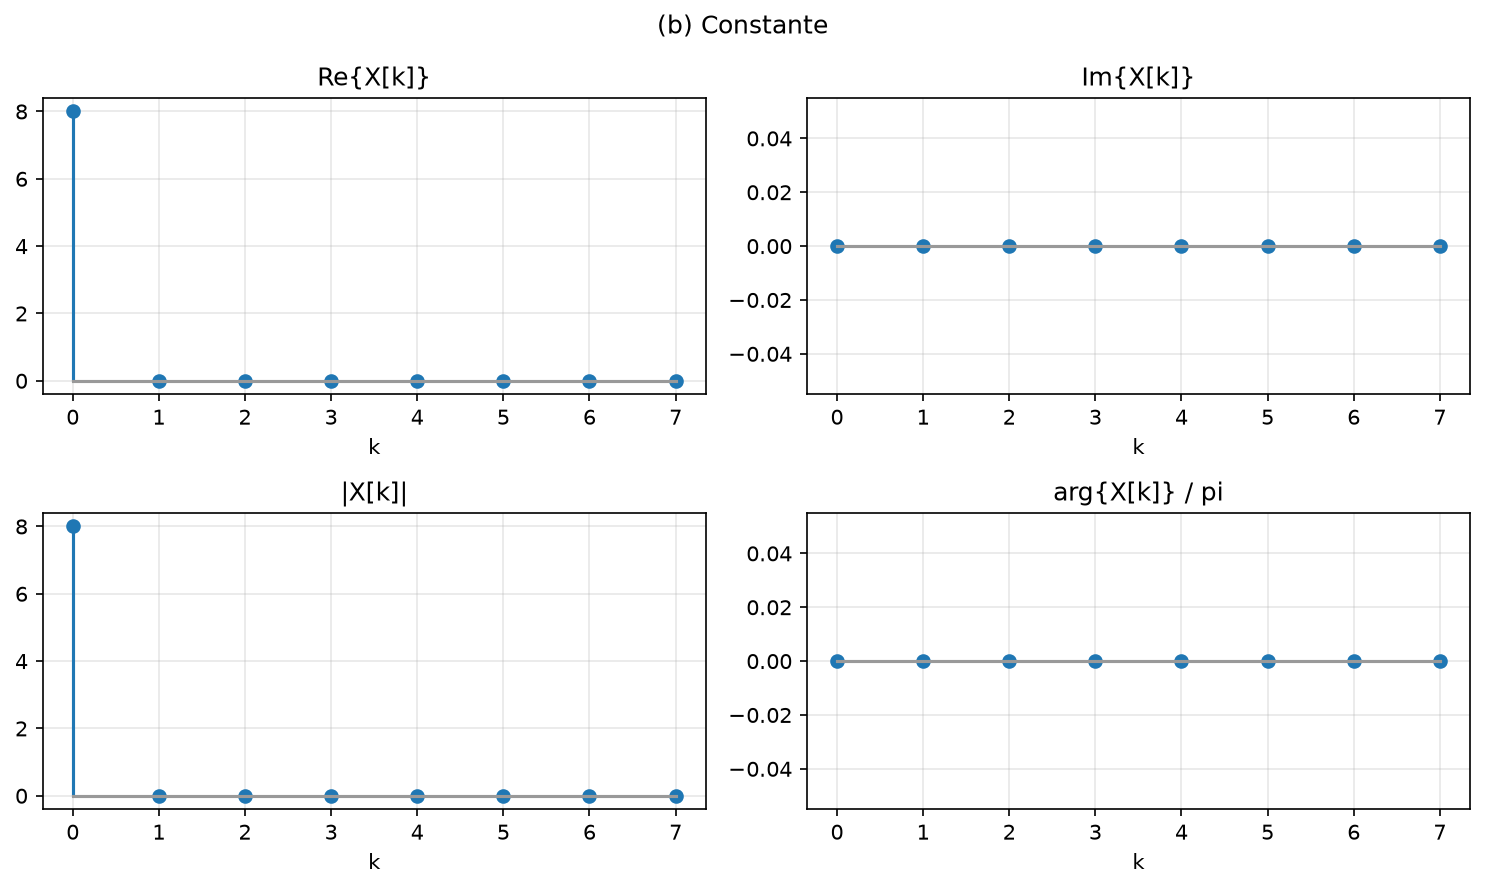

(b)
  h circularmente par   : True
  h circularmente impar : False
  X[-k] = conj(X[k])    : True
  Re par                : True
  Im impar              : True
  |X| par               : True
  X real (Im == 0)      : True
  |X| constante         : False


In [7]:
H_b = plot_dft(h_b, "(b) Constante")
check_symmetry(h_b, "(b)")

$$X^d[k] = [\,8,\;0,\;0,\;0,\;0,\;0,\;0,\;0\,] = 8\,\delta[k]$$

Si la TDF del impulso es la constante 1, entonces la TDF de la constante 1 es $N\,\delta[-k]$, y como el impulso es par eso es $8\,\delta[k]$. De ahí sale el factor $N = 8$.

La señal es constante en el tiempo, toda la energía cae en $k=0$ y no hay nada en el resto de las frecuencias. Lo que está concentrado en un dominio aparece disperso en el otro.

### (c) Impulso corrido  $h[n] = [0\,0\,0\,1\,0\,0\,0\,0]$

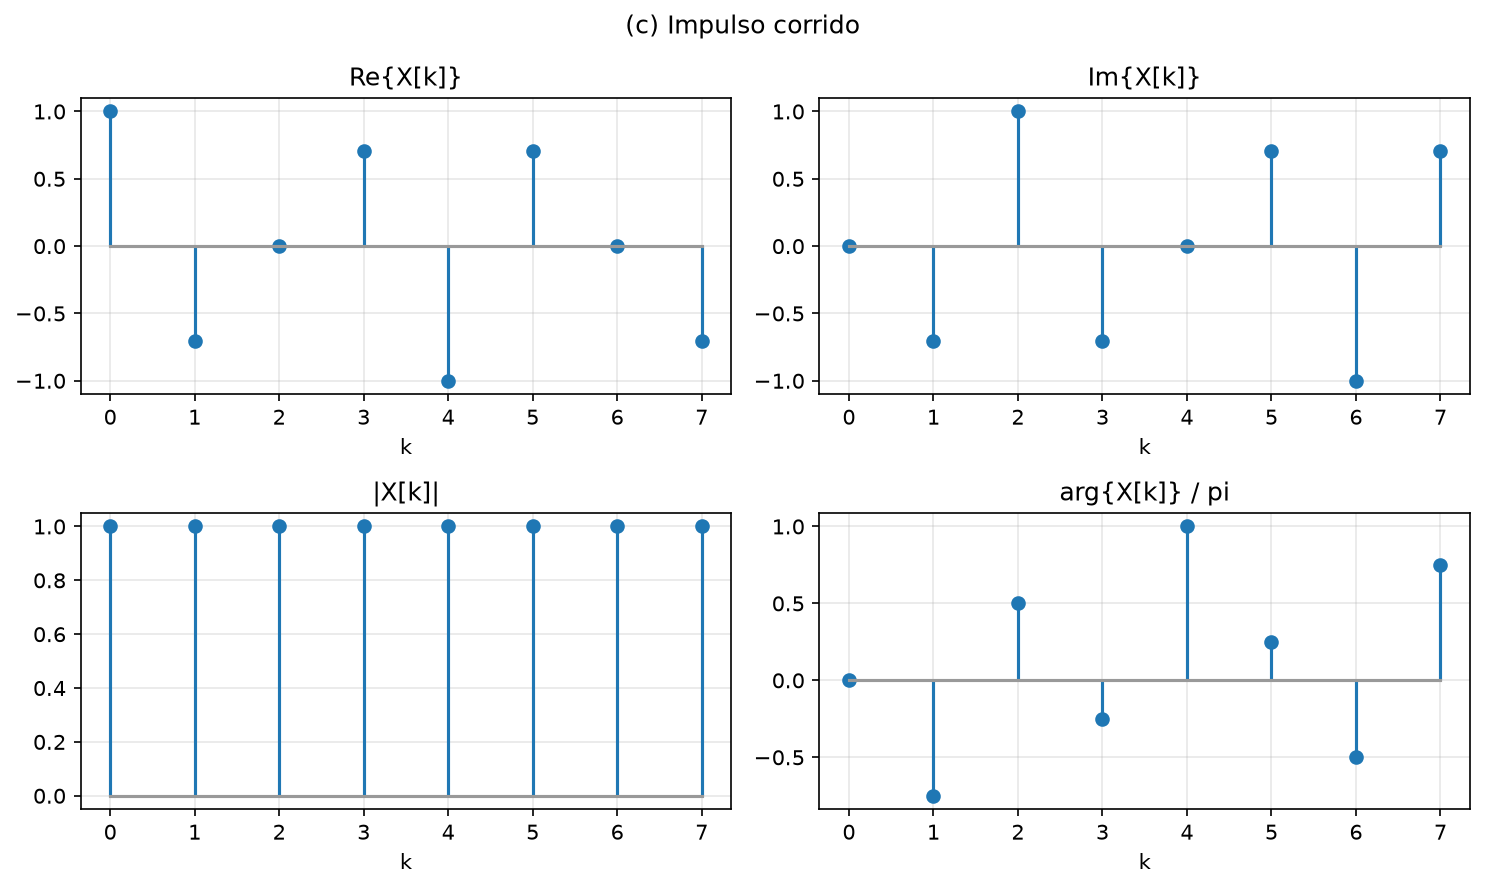

(c)
  h circularmente par   : False
  h circularmente impar : False
  X[-k] = conj(X[k])    : True
  Re par                : True
  Im impar              : True
  |X| par               : True
  X real (Im == 0)      : False
  |X| constante         : True


In [8]:
H_c = plot_dft(h_c, "(c) Impulso corrido")
check_symmetry(h_c, "(c)")

Acá $h[n] = \delta[(n-3)_8]$, así que por la propiedad de desplazamiento circular aplicada
al resultado de (a):

$$X^d[k] = 1 \cdot e^{-j2\pi k \cdot 3/8} = e^{-j3\pi k/4}$$

El módulo sigue valiendo 1 para todo $k$ (correr la señal no cambia el módulo, toda la información del corrimiento queda en la fase). $h[n]$ ya no es circularmente par, y por eso $X^d[k]$ pasa a ser complejo. Como sigue siendo real, se mantienen $\mathrm{Re}$ par e $\mathrm{Im}$ impar.

### (d) Rectángulo  $h[n] = [1\,1\,1\,0\,0\,0\,0\,0]$

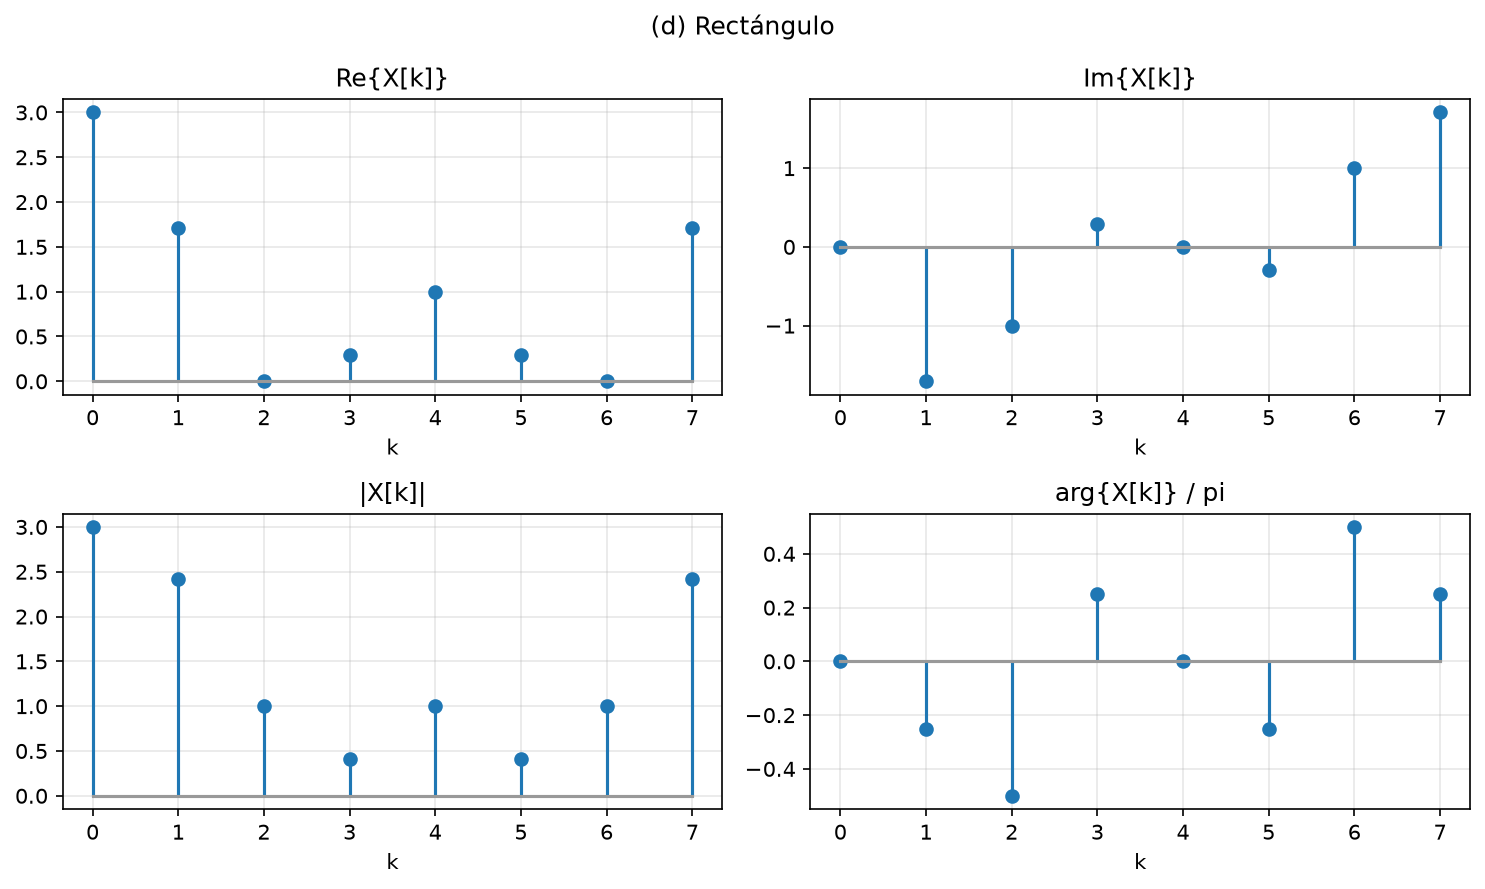

(d)
  h circularmente par   : False
  h circularmente impar : False
  X[-k] = conj(X[k])    : True
  Re par                : True
  Im impar              : True
  |X| par               : True
  X real (Im == 0)      : False
  |X| constante         : False


In [9]:
H_d = plot_dft(h_d, "(d) Rectángulo")
check_symmetry(h_d, "(d)")

$$X^d[k] = \sum_{n=0}^{2} e^{-j2\pi kn/8}$$

La TDF resulta **compleja aunque $h[n]$ sea real**, y la razón es que el rectángulo no
está centrado en el origen: su centro de simetría cae en $n = 1$. Ese corrimiento de una
muestra es el que aporta el factor de fase lineal $e^{-j\pi k/4}$. Como $h[n]$ es real se cumplen igual $\mathrm{Re}$ par, $\mathrm{Im}$ impar y
$\lvert X\rvert$ par.

### (e) Rectángulo simétrico  $h[n] = [1\,1\,0\,0\,0\,0\,0\,1]$

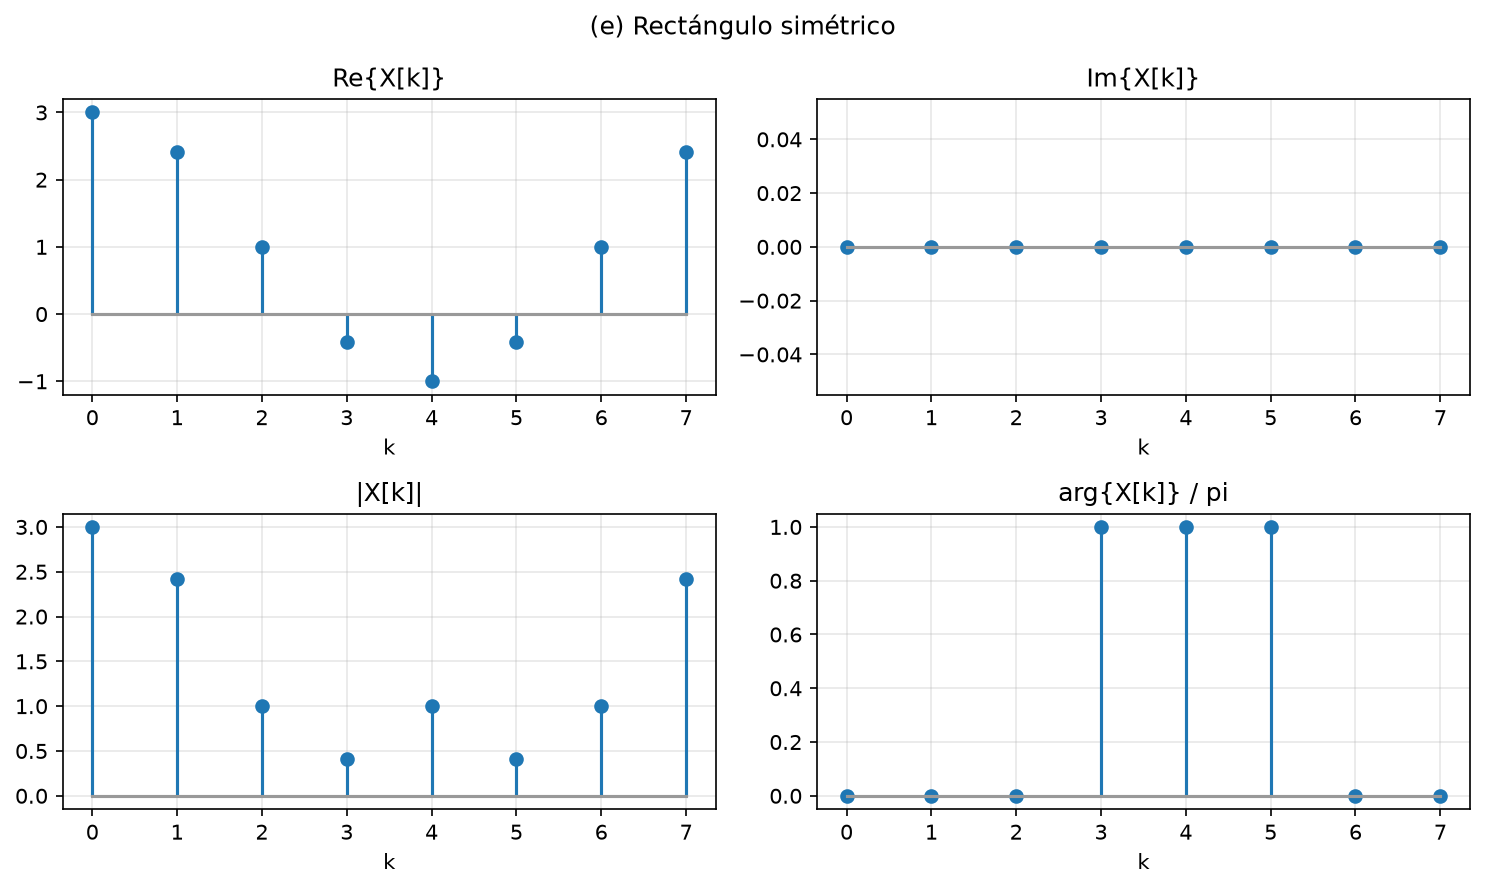

(e)
  h circularmente par   : True
  h circularmente impar : False
  X[-k] = conj(X[k])    : True
  Re par                : True
  Im impar              : True
  |X| par               : True
  X real (Im == 0)      : True
  |X| constante         : False


In [10]:
H_e = plot_dft(h_e, "(e) Rectángulo simétrico")
check_symmetry(h_e, "(e)")

Es el mismo pulso de tres muestras, pero ahora centrado en el origen en sentido
circular: los unos están en $n = 0, 1, 7$, y para $N = 8$ el índice $7$ hace de $-1$.
Entonces $h[(-n)_8] = h[n]$, es decir $h[n]$ es **circularmente par**.

Por la propiedad de simetría, eso obliga a que $X^d[k]$ sea real y par, y efectivamente
la parte imaginaria da cero.

### (f) Señal de largo 8 cuya TDF es $X^d[k] = e^{j5k\pi/8}$

In [12]:
from numpy import exp

k = arange(8)
X_f = exp(1j * 5 * k * pi / 8)
h_f = ifft(X_f)

print("|X_f[k]| :", abs(X_f).round(3))
print()
print("Re{h_f[n]} :", real(h_f).round(4))
print("Im{h_f[n]} :", imag(h_f).round(4))
print()
print("h_f real            :", allclose(imag(h_f), 0))
print("h_f imaginaria pura :", allclose(real(h_f), 0))
print("X[-k] =  conj(X[k]) :", allclose(X_f[(-k) % 8], X_f.conj()))
print("X[-k] = -conj(X[k]) :", allclose(X_f[(-k) % 8], -X_f.conj()))

|X_f[k]| : [1. 1. 1. 1. 1. 1. 1. 1.]

Re{h_f[n]} : [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
Im{h_f[n]} : [ 0.0835  0.0249 -0.0249 -0.0835 -0.1871 -0.6284  0.6284  0.1871]

h_f real            : False
h_f imaginaria pura : False
X[-k] =  conj(X[k]) : False
X[-k] = -conj(X[k]) : False


Primero verifico si la DFT se puede corresponder con un impulso corrido:

$$-\frac{2\pi k n_0}{8} = \frac{5k\pi}{8} \;\Longrightarrow\; n_0 = -\frac{5}{2}$$

$n_0$ **no es entero**, así que $X^d[k]$ no puede ser la TDF de un impulso corrido.

Esto es porque una fase lineal devuelve una señal real sólo si es **impar módulo $N$**, y eso ocurre únicamente cuando $n_0$ es entero. Acá la simetría se rompe, la verificación muestra que no se cumple ni $X[-k] = X^*[k]$ ni $X[-k] = -X^*[k]$ (falla en $k=0$). Por eso la señal obtenida es compleja, con parte real constante $1/8$ y parte
imaginaria no nula.

## Conclusiones

| | $h[n]$ | simetría de $h$ | $X^d[k]$ | explicación |
|---|---|---|---|---|
| a | impulso | circ. par | real, $\lvert X\rvert$ cte | — |
| b | constante | circ. par | real, impulso $\times N$ | dual de (a) |
| c | impulso corrido | ninguna | complejo, $\lvert X\rvert$ cte | (a) + desplazamiento |
| d | rectángulo | ninguna | complejo, Dirichlet | (e) + desplazamiento |
| e | rect. simétrico | circ. par | **real**, Dirichlet | centrado en el origen |
| f | compleja | — | $\lvert X\rvert$ cte | $n_0$ no entero |

Las cinco señales reales cumplen $X^d[N-k] = \left(X^d[k]\right)^*$, y de ahí salen
$\mathrm{Re}$ par, $\mathrm{Im}$ impar, $\lvert X\rvert$ par y fase impar.

La columna que decide todo es la simetría circular de $h[n]$: cuando además de real es
circularmente par (a, b, e), la TDF sale **real**; cuando no lo es (c, d), aparece parte
imaginaria. Comparar (d) con (e) lo aísla bien, porque son el mismo rectángulo y sólo
difieren en estar o no centrado.

La dualidad explica el par (a)/(b), y la propiedad de desplazamiento explica (c) a partir
de (a) y (d) a partir de (e): en ambos casos el módulo queda intacto y el corrimiento se
va entero a la fase. El inciso (f) muestra el límite de esa propiedad, porque sólo vale
para corrimientos enteros.